# **Analisis Statistik Berpasangan — Ketahanan Bahasa Lokal V5 Batch 80**

---

**Proyek:** KP Agentic AI + LLM  
**Tahap:** Analisis statistik setelah audit V5  
**Dataset:** MASSIVE-Agents — development  
**Eksperimen:** 80 variasi × 4 model, perbandingan instruksi asli dan variasi

Analisis menggunakan prediksi yang telah tersimpan dari eksperimen sebelumnya. Dua populasi dilaporkan secara terpisah: Batch 80 utuh dan subset sensitivitas 70 variasi yang tidak ditahan oleh tinjauan AI. Tidak ada inferensi model atau perubahan ground truth.

## **1. Dataset dan Konfigurasi Analisis**

---

Data berpasangan diambil dari hasil analisis pasca-audit V5. Setiap baris mewakili satu kombinasi model dan variasi, dengan status ketepatan AST dan Function Selection Accuracy (FSA) pada instruksi asli serta variasinya. Perhitungan statistik menggunakan **exact McNemar** per model, penyesuaian Holm, dan resampling berdasarkan kelompok instruksi induk.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
from math import comb
import hashlib
import json
import numpy as np
import pandas as pd
from IPython.display import display

SEED = 20261117
BOOTSTRAP_REPS = 20000
PERMUTATION_REPS = 100000
METRICS = {"ast": "BFCL AST", "fsa": "FSA"}
MODELS_ORDER = [
    "qwen2.5:7b-instruct",
    "gemma2:9b-instruct-q4_K_M",
    "Supa-AI/gemma2-9b-cpt-sahabatai-v1-instruct:q4_k_m",
    "lfm2.5:8b-a1b-q4_K_M",
]


def find_root():
    here = Path.cwd().resolve()
    candidates = [here, *here.parents, Path(r"D:\KP-Agentic-AI")]
    for candidate in candidates:
        source = (candidate / "results" / "ketahanan_bahasa_lokal" /
                  "eksplorasi_v5_batch80" / "analisis_pasca_audit_v5" /
                  "hasil_berpasangan_dengan_audit.csv")
        if source.is_file():
            return candidate
    raise FileNotFoundError("File hasil_berpasangan_dengan_audit.csv tidak ditemukan di hasil analisis pasca-audit.")

ROOT = find_root()
BASE = ROOT / "results" / "ketahanan_bahasa_lokal" / "eksplorasi_v5_batch80"
SOURCE = BASE / "analisis_pasca_audit_v5" / "hasil_berpasangan_dengan_audit.csv"
OUTPUT = BASE / "analisis_statistik_v5_batch80"
raw = pd.read_csv(SOURCE, dtype={"variant_id": "string", "group_id": "string"})
print("Sumber:", SOURCE)
print("Baris prediksi:", len(raw))

Sumber: D:\KP-Agentic-AI\results\ketahanan_bahasa_lokal\eksplorasi_v5_batch80\analisis_pasca_audit_v5\hasil_berpasangan_dengan_audit.csv
Baris prediksi: 320


## **2. Pemeriksaan Integritas Pasangan**

---

Setiap variasi harus memiliki empat prediksi dari model yang berbeda, dan setiap `group_id` harus merujuk pada satu instruksi induk. Status ketepatan dinormalisasi menjadi nilai biner sebelum analisis. Pembagian 80/70/10 dipertahankan sesuai keputusan audit; kelompok non-ditahan **belum dianggap tervalidasi manusia**.

In [2]:
REQUIRED = ["variant_id", "group_id", "kategori", "model", "kelompok_audit",
            "ast_original_correct", "ast_variasi_correct",
            "fsa_original_correct", "fsa_variasi_correct"]
assert set(REQUIRED).issubset(raw.columns), "Kolom utama analisis tidak lengkap."
assert not raw[REQUIRED].isna().any().any(), "Ada nilai kosong pada kolom utama."

df = raw.copy()
for col in ("ast_original_correct", "ast_variasi_correct",
            "fsa_original_correct", "fsa_variasi_correct"):
    values = df[col].astype(str).str.strip().str.lower()
    assert values.isin(["true", "false"]).all(), f"Nilai boolean tidak sesuai: {col}"
    df[col] = values.eq("true")

assert len(df) == 320
assert not df.duplicated(["model", "variant_id"]).any()
assert df["variant_id"].nunique() == 80
assert df["group_id"].nunique() == 80
assert set(df["model"]) == set(MODELS_ORDER)
assert df.groupby("variant_id")["model"].nunique().eq(4).all()
assert df.groupby("variant_id")["group_id"].nunique().eq(1).all()
assert df.groupby("group_id")["variant_id"].nunique().eq(1).all()
assert df.groupby("variant_id")["kelompok_audit"].nunique().eq(1).all()
assert df.groupby("variant_id")["kategori"].nunique().eq(1).all()
assert set(df["kelompok_audit"]) == {"NON_DITAHAN_AI", "DITAHAN_AI"}
assert not (df["ast_original_correct"] & ~df["fsa_original_correct"]).any()
assert not (df["ast_variasi_correct"] & ~df["fsa_variasi_correct"]).any()

all80 = df.copy()
subset70 = df.loc[df["kelompok_audit"].eq("NON_DITAHAN_AI")].copy()
held10 = df.loc[df["kelompok_audit"].eq("DITAHAN_AI")].copy()
assert (len(subset70), subset70["variant_id"].nunique()) == (280, 70)
assert (len(held10), held10["variant_id"].nunique()) == (40, 10)
assert set(subset70["group_id"]).isdisjoint(held10["group_id"])

GROUPS = {"BATCH80_UTUH": all80, "NON_DITAHAN_AI_70": subset70}
print("Integritas: PASS | 80 group_id unik | 4 model per variasi")
print("Batch utuh:", len(all80), "prediksi | Subset non-ditahan:", len(subset70), "prediksi")

Integritas: PASS | 80 group_id unik | 4 model per variasi
Batch utuh: 320 prediksi | Subset non-ditahan: 280 prediksi


## **3. Perubahan Ketepatan pada Pasangan yang Sama**

---

Selisih dihitung sebagai persentase variasi dikurangi persentase instruksi asli, dalam satuan poin persentase (*percentage points*). Transisi benar→salah dan salah→benar dipisahkan karena hanya kedua kelompok tersebut yang berkontribusi pada uji McNemar.

In [3]:
def counts(subset, metric):
    a = subset[f"{metric}_original_correct"].to_numpy(dtype=bool)
    v = subset[f"{metric}_variasi_correct"].to_numpy(dtype=bool)
    return {
        "tetap_benar": int(np.sum(a & v)),
        "benar_ke_salah": int(np.sum(a & ~v)),
        "salah_ke_benar": int(np.sum(~a & v)),
        "tetap_salah": int(np.sum(~a & ~v)),
        "asli_benar": int(a.sum()),
        "variasi_benar": int(v.sum()),
    }

summary_rows = []
for label, subset in GROUPS.items():
    for metric, title in METRICS.items():
        c = counts(subset, metric)
        n = len(subset)
        assert sum(c[k] for k in ("tetap_benar", "benar_ke_salah", "salah_ke_benar", "tetap_salah")) == n
        assert c["asli_benar"] - c["variasi_benar"] == c["benar_ke_salah"] - c["salah_ke_benar"]
        summary_rows.append({"kelompok": label, "metrik": title,
                             "n_variasi": subset["variant_id"].nunique(), "n_prediksi": n,
                             **c, "asli_pct": 100 * c["asli_benar"] / n,
                             "variasi_pct": 100 * c["variasi_benar"] / n,
                             "delta_pp": 100 * (c["variasi_benar"] - c["asli_benar"]) / n})
summary = pd.DataFrame(summary_rows)
assert int(summary.loc[0, "asli_benar"]) == 45 and int(summary.loc[0, "variasi_benar"]) == 39
assert int(summary.loc[1, "asli_benar"]) == 230 and int(summary.loc[1, "variasi_benar"]) == 212
assert int(summary.loc[2, "asli_benar"]) == 44 and int(summary.loc[2, "variasi_benar"]) == 37
assert int(summary.loc[3, "asli_benar"]) == 214 and int(summary.loc[3, "variasi_benar"]) == 200
display(summary.round(3))

,kelompok,metrik,n_variasi,n_prediksi,tetap_benar,benar_ke_salah,salah_ke_benar,tetap_salah,asli_benar,variasi_benar,asli_pct,variasi_pct,delta_pp
0,BATCH80_UTUH,BFCL AST,80,320,31,14,8,267,45,39,14.062,12.188,-1.875
1,BATCH80_UTUH,FSA,80,320,202,28,10,80,230,212,71.875,66.250,-5.625
2,NON_DITAHAN_AI_70,BFCL AST,70,280,31,13,6,230,44,37,15.714,13.214,-2.500
3,NON_DITAHAN_AI_70,FSA,70,280,191,23,9,57,214,200,76.429,71.429,-5.000


## **4. Exact McNemar per Model**

---

Uji McNemar menggunakan pasangan biner sebelum dan sesudah variasi pada **80 instruksi yang sama untuk setiap model**, atau 70 instruksi pada subset sensitivitas. Hipotesis nol menyatakan peluang perubahan benar→salah sama dengan salah→benar. Nilai p dihitung secara eksak melalui distribusi binomial atas pasangan tidak selaras, tanpa pendekatan chi-square, sehingga tetap sesuai untuk jumlah perubahan yang kecil.

In [4]:
def exact_mcnemar(b, c):
    discordant = int(b + c)
    if discordant == 0:
        return 1.0
    small = min(int(b), int(c))
    return min(1.0, 2.0 * sum(comb(discordant, k) for k in range(small + 1)) / (2 ** discordant))

mcnemar_rows = []
for label, subset in GROUPS.items():
    for metric, title in METRICS.items():
        for model in MODELS_ORDER:
            one = subset.loc[subset["model"].eq(model)]
            c = counts(one, metric)
            b = c["benar_ke_salah"]
            d = c["salah_ke_benar"]
            mcnemar_rows.append({"kelompok": label, "metrik": title, "model": model,
                                 "n_pasangan": len(one), "tetap_benar": c["tetap_benar"],
                                 "benar_ke_salah": b, "salah_ke_benar": d,
                                 "tetap_salah": c["tetap_salah"], "discordant": b+d,
                                 "asli_benar": c["asli_benar"], "variasi_benar": c["variasi_benar"],
                                 "delta_pp": 100.0*(d-b)/len(one), "p_exact": exact_mcnemar(b,d)})
mcnemar = pd.DataFrame(mcnemar_rows)
assert len(mcnemar) == 16
assert mcnemar.loc[mcnemar["kelompok"].eq("BATCH80_UTUH"), "n_pasangan"].eq(80).all()
assert mcnemar.loc[mcnemar["kelompok"].eq("NON_DITAHAN_AI_70"), "n_pasangan"].eq(70).all()
display(mcnemar.loc[mcnemar["kelompok"].eq("BATCH80_UTUH")].round(5))

,kelompok,metrik,model,n_pasangan,tetap_benar,benar_ke_salah,salah_ke_benar,tetap_salah,discordant,asli_benar,variasi_benar,delta_pp,p_exact
0,BATCH80_UTUH,BFCL AST,qwen2.5:7b-instruct,80,13,4,2,61,6,17,15,-2.50,0.68750
1,BATCH80_UTUH,BFCL AST,gemma2:9b-instruct-q4_K_M,80,6,2,2,70,4,8,8,0.00,1.00000
2,BATCH80_UTUH,BFCL AST,Supa-AI/gemma2-9b-cpt-sahabatai-v1-instruct:q4...,80,11,4,4,61,8,15,15,0.00,1.00000
3,BATCH80_UTUH,BFCL AST,lfm2.5:8b-a1b-q4_K_M,80,1,4,0,75,4,5,1,-5.00,0.12500
4,BATCH80_UTUH,FSA,qwen2.5:7b-instruct,80,62,8,1,9,9,70,63,-8.75,0.03906
5,BATCH80_UTUH,FSA,gemma2:9b-instruct-q4_K_M,80,56,6,3,15,9,62,59,-3.75,0.50781
6,BATCH80_UTUH,FSA,Supa-AI/gemma2-9b-cpt-sahabatai-v1-instruct:q4...,80,61,3,3,13,6,64,64,0.00,1.00000
7,BATCH80_UTUH,FSA,lfm2.5:8b-a1b-q4_K_M,80,23,11,3,43,14,34,26,-10.00,0.05737


## **5. Koreksi Holm dan Interpretasi Pengujian Model**

---

Penyesuaian Holm diterapkan pada **empat model dalam setiap kombinasi metrik dan kelompok data**. Hasil pada subset 70 dilaporkan sebagai analisis sensitivitas, bukan uji konfirmasi baru. `p ≥ 0,05` tidak membuktikan ketahanan model sama; nilai p harus dibaca bersama besar perubahan dan jumlah pasangan tidak selaras.

In [5]:
def holm_adjust(p_values):
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p, kind="stable")
    sorted_p = p[order]
    adjusted_sorted = np.maximum.accumulate(np.minimum(1.0, sorted_p * (len(p) - np.arange(len(p)))))
    out = np.empty(len(p), dtype=float)
    out[order] = np.minimum(1.0, adjusted_sorted)
    return out

mcnemar["p_holm_4model"] = np.nan
for (_, _), ids in mcnemar.groupby(["kelompok", "metrik"], sort=False).groups.items():
    ix = list(ids)
    mcnemar.loc[ix, "p_holm_4model"] = holm_adjust(mcnemar.loc[ix, "p_exact"].values)
mcnemar["signifikan_holm_005"] = mcnemar["p_holm_4model"] < 0.05
assert mcnemar["p_holm_4model"].ge(mcnemar["p_exact"] - 1e-12).all()
display(mcnemar[["kelompok", "metrik", "model", "benar_ke_salah", "salah_ke_benar",
                 "delta_pp", "p_exact", "p_holm_4model", "signifikan_holm_005"]].round(5))

,kelompok,metrik,model,benar_ke_salah,salah_ke_benar,delta_pp,p_exact,p_holm_4model,signifikan_holm_005
0,BATCH80_UTUH,BFCL AST,qwen2.5:7b-instruct,4,2,-2.50000,0.68750,1.00000,False
1,BATCH80_UTUH,BFCL AST,gemma2:9b-instruct-q4_K_M,2,2,0.00000,1.00000,1.00000,False
2,BATCH80_UTUH,BFCL AST,Supa-AI/gemma2-9b-cpt-sahabatai-v1-instruct:q4...,4,4,0.00000,1.00000,1.00000,False
3,BATCH80_UTUH,BFCL AST,lfm2.5:8b-a1b-q4_K_M,4,0,-5.00000,0.12500,0.50000,False
4,BATCH80_UTUH,FSA,qwen2.5:7b-instruct,8,1,-8.75000,0.03906,0.15625,False
5,BATCH80_UTUH,FSA,gemma2:9b-instruct-q4_K_M,6,3,-3.75000,0.50781,1.00000,False
6,BATCH80_UTUH,FSA,Supa-AI/gemma2-9b-cpt-sahabatai-v1-instruct:q4...,3,3,0.00000,1.00000,1.00000,False
7,BATCH80_UTUH,FSA,lfm2.5:8b-a1b-q4_K_M,11,3,-10.00000,0.05737,0.17212,False
8,NON_DITAHAN_AI_70,BFCL AST,qwen2.5:7b-instruct,4,2,-2.85714,0.68750,1.00000,False
9,NON_DITAHAN_AI_70,BFCL AST,gemma2:9b-instruct-q4_K_M,2,2,0.00000,1.00000,1.00000,False


## **6. Analisis Gabungan dengan Kelompok Instruksi**

---

Keempat model menggunakan **instruksi induk yang sama**, sehingga 320 hasil model tidak diperlakukan sebagai 320 observasi independen pada uji gabungan. Setiap `group_id` dijadikan unit resampling. Selisih ketepatan empat model diringkas per instruksi, lalu dihitung **95% bootstrap confidence interval** melalui pengambilan ulang kelompok serta **uji permutasi Monte Carlo dua sisi** dengan pertukaran tanda selisih pada tingkat kelompok. Untuk Batch 80, nilai p pada dua metrik utama dikoreksi menggunakan Holm. Uji gabungan ini bersifat eksploratif dan bergantung pada asumsi pertukaran label asli–variasi di bawah hipotesis nol.

In [6]:
def clustered_delta(subset, metric, seed):
    work = subset[["group_id", f"{metric}_original_correct", f"{metric}_variasi_correct"]].copy()
    work["delta"] = (work[f"{metric}_variasi_correct"].astype(int) -
                     work[f"{metric}_original_correct"].astype(int))
    groups = work.groupby("group_id", sort=True)["delta"].mean().to_numpy(dtype=float)
    n_groups = len(groups)
    assert n_groups == subset["variant_id"].nunique()
    assert work.groupby("group_id").size().eq(4).all()
    effect_pp = 100.0 * groups.mean()

    rng = np.random.default_rng(seed)
    bootstrap = np.empty(BOOTSTRAP_REPS, dtype=float)
    chunk = 2000
    for start in range(0, BOOTSTRAP_REPS, chunk):
        size = min(chunk, BOOTSTRAP_REPS - start)
        draw = rng.integers(0, n_groups, size=(size, n_groups))
        bootstrap[start:start+size] = groups[draw].mean(axis=1) * 100.0
    ci_low, ci_high = np.quantile(bootstrap, [0.025, 0.975])

    observed = abs(groups.mean())
    exceed = 0
    for start in range(0, PERMUTATION_REPS, chunk):
        size = min(chunk, PERMUTATION_REPS - start)
        signs = 2 * rng.integers(0, 2, size=(size, n_groups)) - 1
        simulated = abs((signs * groups).mean(axis=1))
        exceed += int(np.sum(simulated >= observed - 1e-12))
    p_mc = (exceed + 1) / (PERMUTATION_REPS + 1)
    return {"n_group_id": n_groups, "n_prediksi": len(subset),
            "delta_pp": effect_pp, "bootstrap_ci95_bawah_pp": ci_low,
            "bootstrap_ci95_atas_pp": ci_high, "p_permutasi_mc": p_mc,
            "bootstrap_reps": BOOTSTRAP_REPS, "permutasi_reps": PERMUTATION_REPS}

cluster_rows = []
for i, (label, subset) in enumerate(GROUPS.items()):
    for j, (metric, title) in enumerate(METRICS.items()):
        cluster_rows.append({"kelompok": label, "metrik": title,
                             **clustered_delta(subset, metric, SEED+i*10+j)})
cluster_stats = pd.DataFrame(cluster_rows)
for i, row in cluster_stats.iterrows():
    expected = float(summary[(summary["kelompok"] == row["kelompok"]) &
                             (summary["metrik"] == row["metrik"])]["delta_pp"].iloc[0])
    assert np.isclose(row["delta_pp"], expected)
cluster_stats["p_holm_2_metrik_batch80"] = np.nan
primary_ix = cluster_stats.index[cluster_stats["kelompok"].eq("BATCH80_UTUH")].tolist()
cluster_stats.loc[primary_ix, "p_holm_2_metrik_batch80"] = holm_adjust(
    cluster_stats.loc[primary_ix, "p_permutasi_mc"].values
)
display(cluster_stats.round(5))

,kelompok,metrik,n_group_id,n_prediksi,delta_pp,bootstrap_ci95_bawah_pp,bootstrap_ci95_atas_pp,p_permutasi_mc,bootstrap_reps,permutasi_reps,p_holm_2_metrik_batch80
0,BATCH80_UTUH,BFCL AST,80,320,-1.875,-5.00000,1.56250,0.37378,20000,100000,0.37378
1,BATCH80_UTUH,FSA,80,320,-5.625,-10.00000,-1.25000,0.01615,20000,100000,0.03230
2,NON_DITAHAN_AI_70,BFCL AST,70,280,-2.500,-6.07143,1.07143,0.25541,20000,100000,NaN
3,NON_DITAHAN_AI_70,FSA,70,280,-5.000,-9.64286,-0.71429,0.04703,20000,100000,NaN


## **7. Perubahan per Kategori Bahasa**

---

Kategori slang, singkatan, typo, dan code-switching ID–EN masing-masing memiliki 20 variasi pada Batch 80 utuh. Perubahan per kategori diringkas sebagai analisis deskriptif; uji signifikansi per kategori tidak dijadikan dasar kesimpulan karena jumlah pasangan dan perubahan benar–salah yang terbatas.

In [7]:
category_rows = []
for label, subset in GROUPS.items():
    for category, part in subset.groupby("kategori", sort=True):
        for metric, title in METRICS.items():
            c = counts(part, metric)
            category_rows.append({"kelompok": label, "kategori": category, "metrik": title,
                                  "n_variants": part["variant_id"].nunique(), "n_prediksi": len(part),
                                  "asli_benar": c["asli_benar"], "variasi_benar": c["variasi_benar"],
                                  "benar_ke_salah": c["benar_ke_salah"],
                                  "salah_ke_benar": c["salah_ke_benar"],
                                  "delta_pp": 100*(c["variasi_benar"]-c["asli_benar"])/len(part)})
categories = pd.DataFrame(category_rows)
display(categories.round(3))

,kelompok,kategori,metrik,n_variants,n_prediksi,asli_benar,variasi_benar,benar_ke_salah,salah_ke_benar,delta_pp
0,BATCH80_UTUH,code_switch_id_en,BFCL AST,20,80,8,9,4,5,1.250
1,BATCH80_UTUH,code_switch_id_en,FSA,20,80,53,55,5,7,2.500
2,BATCH80_UTUH,singkatan,BFCL AST,20,80,5,5,2,2,0.000
3,BATCH80_UTUH,singkatan,FSA,20,80,57,57,2,2,0.000
4,BATCH80_UTUH,slang,BFCL AST,20,80,20,18,2,0,-2.500
5,BATCH80_UTUH,slang,FSA,20,80,65,59,6,0,-7.500
6,BATCH80_UTUH,typo,BFCL AST,20,80,12,7,6,1,-6.250
7,BATCH80_UTUH,typo,FSA,20,80,55,41,15,1,-17.500
8,NON_DITAHAN_AI_70,code_switch_id_en,BFCL AST,15,60,7,8,3,4,1.667
9,NON_DITAHAN_AI_70,code_switch_id_en,FSA,15,60,42,47,1,6,8.333


## **8. Validasi Perhitungan dan Batas Inferensi**

---

Kesesuaian hasil diuji terhadap ringkasan pasca-audit, termasuk perubahan AST 14 benar→salah dan 8 salah→benar pada Batch 80. Analisis statistik tidak menghapus 10 kasus yang ditahan dari pelaporan utama. Tidak ada klaim signifikansi dari gabungan McNemar 320 baris, karena antarmodel berbagi instruksi yang sama. Status audit AI juga tidak menggantikan validasi semantik manusia.

In [8]:
raw_ast = counts(all80, "ast")
raw_fsa = counts(all80, "fsa")
assert (raw_ast["benar_ke_salah"], raw_ast["salah_ke_benar"]) == (14, 8)
assert (raw_fsa["benar_ke_salah"], raw_fsa["salah_ke_benar"]) == (28, 10)
for label, subset in GROUPS.items():
    for metric in METRICS:
        part = mcnemar[(mcnemar["kelompok"] == label) & (mcnemar["metrik"] == METRICS[metric])]
        c = counts(subset, metric)
        assert int(part["benar_ke_salah"].sum()) == c["benar_ke_salah"]
        assert int(part["salah_ke_benar"].sum()) == c["salah_ke_benar"]
        assert int(part["asli_benar"].sum()) == c["asli_benar"]
        assert int(part["variasi_benar"].sum()) == c["variasi_benar"]

print("Pemeriksaan konsistensi: PASS")
print("McNemar: per model, bukan gabungan 320 baris")
print("Resampling: per group_id, 80 kelompok atau 70 kelompok")
print("Inferensi model: tidak diulang | GT: tidak diubah | Split test: tidak digunakan")
print("Validasi manusia: PENDING")

Pemeriksaan konsistensi: PASS
McNemar: per model, bukan gabungan 320 baris
Resampling: per group_id, 80 kelompok atau 70 kelompok
Inferensi model: tidak diulang | GT: tidak diubah | Split test: tidak digunakan
Validasi manusia: PENDING


## **9. Dokumentasi Hasil Statistik**

---

Hasil analisis disimpan terpisah dari output inferensi dan audit sebelumnya. Tabel meliputi perbandingan skor, uji McNemar per model, ringkasan gabungan berbasis kelompok, dan rincian kategori. Metadata mencatat identitas sumber, jumlah resampling, serta batas penggunaan hasil.

In [9]:
OUTPUT.mkdir(parents=True, exist_ok=True)
outputs = {
    "statistik_mcnemar_per_model.csv": mcnemar,
    "statistik_gabungan_berbasis_group.csv": cluster_stats,
    "ringkasan_statistik_80_70.csv": summary,
    "statistik_per_kategori_deskriptif.csv": categories,
}
for name, table in outputs.items():
    table.to_csv(OUTPUT / name, index=False, encoding="utf-8-sig")

meta = {
    "run": "analisis_statistik_v5_batch80",
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "source_file": str(SOURCE.relative_to(ROOT)).replace("\\", "/"),
    "source_sha256": hashlib.sha256(SOURCE.read_bytes()).hexdigest(),
    "split": "development", "total_variations": 80, "total_predictions": 320,
    "sensitivity_variations": 70, "sensitivity_predictions": 280,
    "models": MODELS_ORDER,
    "methods": ["exact_mcnemar_per_model", "holm_per_metric_and_subset_across_4_models",
                "group_id_cluster_bootstrap", "group_id_paired_sign_flip_mc"],
    "random_seed": SEED, "bootstrap_reps": BOOTSTRAP_REPS,
    "permutation_reps": PERMUTATION_REPS,
    "human_validation": "PENDING", "test_used": False,
    "model_inference_repeated": False, "GT_modified": False,
    "status": "development_exploratory_statistical_analysis",
    "limitations": ["Subset 70 berasal dari tinjauan AI, bukan validasi manusia.",
                    "Empat model berbagi group_id; tidak ada uji McNemar gabungan 320 observasi.",
                    "Uji per kategori hanya deskriptif; inferensi gabungan berbasis resampling kelompok."]
}
(OUTPUT / "metadata_statistik.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
print("Hasil tersimpan:", len(outputs), "CSV + metadata_statistik.json")
print("Lokasi:", OUTPUT)

Hasil tersimpan: 4 CSV + metadata_statistik.json
Lokasi: D:\KP-Agentic-AI\results\ketahanan_bahasa_lokal\eksplorasi_v5_batch80\analisis_statistik_v5_batch80


## **10. Ringkasan Hasil Statistik**

---

Analisis membedakan besar perubahan skor dan kekuatan bukti statistiknya. Hasil utama berasal dari Batch 80, sedangkan subset 70 digunakan untuk melihat apakah arah perubahan tetap terlihat setelah kandidat yang ditahan oleh audit AI dikeluarkan. Kesimpulan tentang ketahanan bahasa lokal tetap dibatasi oleh ukuran sampel, penggunaan development set, dan belum selesainya validasi manusia.

In [10]:
for label in GROUPS:
    print("\n" + label)
    for metric, title in METRICS.items():
        stat = cluster_stats.loc[(cluster_stats["kelompok"] == label) &
                                 (cluster_stats["metrik"] == title)].iloc[0]
        print(f"  {title}: delta {stat['delta_pp']:+.2f} pp | ",
              f"CI bootstrap 95% [{stat['bootstrap_ci95_bawah_pp']:+.2f}, ",
              f"{stat['bootstrap_ci95_atas_pp']:+.2f}] pp | ",
              f"p permutasi kelompok = {stat['p_permutasi_mc']:.4f}", sep="")
print("\nMcNemar per model (Batch 80; p Holm):")
display(mcnemar.loc[mcnemar["kelompok"].eq("BATCH80_UTUH"),
                    ["model", "metrik", "delta_pp", "benar_ke_salah", "salah_ke_benar",
                     "p_exact", "p_holm_4model", "signifikan_holm_005"]].round(5))
print("\nStatus penelitian: eksploratif; validasi manusia belum selesai.")


BATCH80_UTUH
  BFCL AST: delta -1.88 pp | CI bootstrap 95% [-5.00, +1.56] pp | p permutasi kelompok = 0.3738
  FSA: delta -5.62 pp | CI bootstrap 95% [-10.00, -1.25] pp | p permutasi kelompok = 0.0161

NON_DITAHAN_AI_70
  BFCL AST: delta -2.50 pp | CI bootstrap 95% [-6.07, +1.07] pp | p permutasi kelompok = 0.2554
  FSA: delta -5.00 pp | CI bootstrap 95% [-9.64, -0.71] pp | p permutasi kelompok = 0.0470

McNemar per model (Batch 80; p Holm):


,model,metrik,delta_pp,benar_ke_salah,salah_ke_benar,p_exact,p_holm_4model,signifikan_holm_005
0,qwen2.5:7b-instruct,BFCL AST,-2.50,4,2,0.68750,1.00000,False
1,gemma2:9b-instruct-q4_K_M,BFCL AST,0.00,2,2,1.00000,1.00000,False
2,Supa-AI/gemma2-9b-cpt-sahabatai-v1-instruct:q4...,BFCL AST,0.00,4,4,1.00000,1.00000,False
3,lfm2.5:8b-a1b-q4_K_M,BFCL AST,-5.00,4,0,0.12500,0.50000,False
4,qwen2.5:7b-instruct,FSA,-8.75,8,1,0.03906,0.15625,False
5,gemma2:9b-instruct-q4_K_M,FSA,-3.75,6,3,0.50781,1.00000,False
6,Supa-AI/gemma2-9b-cpt-sahabatai-v1-instruct:q4...,FSA,0.00,3,3,1.00000,1.00000,False
7,lfm2.5:8b-a1b-q4_K_M,FSA,-10.00,11,3,0.05737,0.17212,False



Status penelitian: eksploratif; validasi manusia belum selesai.


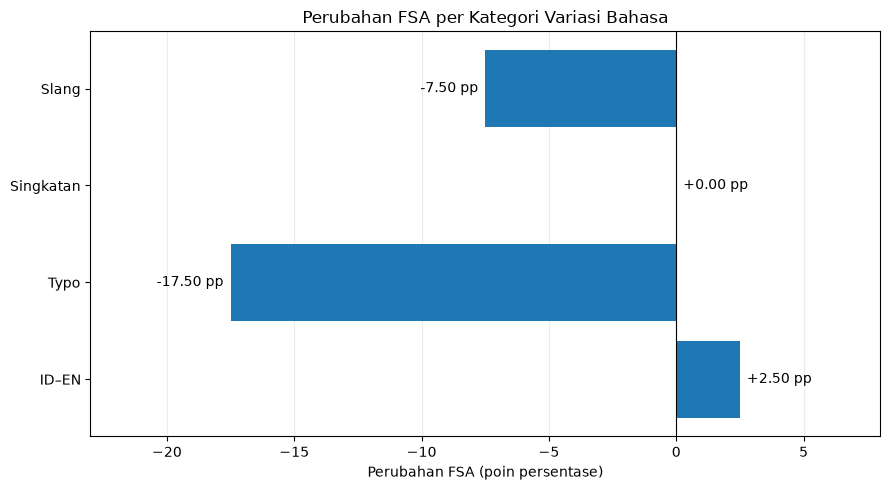

In [14]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("default")

# Membaca hasil statistik per kategori
path = Path(
    r"D:\KP-Agentic-AI\results\ketahanan_bahasa_lokal"
    r"\eksplorasi_v5_batch80\analisis_statistik_v5_batch80"
    r"\statistik_per_kategori_deskriptif.csv"
)

df = pd.read_csv(path)

data = df[
    (df["kelompok"] == "BATCH80_UTUH") &
    (df["metrik"] == "FSA")
].copy()

kategori = ["slang", "singkatan", "typo", "code_switch_id_en"]
label = ["Slang", "Singkatan", "Typo", "ID–EN"]

data = data.set_index("kategori").loc[kategori]
nilai = data["delta_pp"].astype(float).tolist()

# Visualisasi perubahan FSA
fig, ax = plt.subplots(figsize=(9, 5))

ax.barh(label, nilai)
ax.axvline(0, color="black", linewidth=0.8)

for i, v in enumerate(nilai):
    ax.annotate(
        f"{v:+.2f} pp",
        xy=(v, i),
        xytext=(5 if v >= 0 else -5, 0),
        textcoords="offset points",
        ha="left" if v >= 0 else "right",
        va="center"
    )

ax.set_title("Perubahan FSA per Kategori Variasi Bahasa")
ax.set_xlabel("Perubahan FSA (poin persentase)")
ax.set_xlim(-23, 8)
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()
